# 01 Eksplorasi Data (EDA)

Notebook ini memeriksa data mentah di `data/raw/` sebelum preprocessing.

Urutan pipeline: `00_generate_dataset.py` → `01_eksplorasi.ipynb` → `02_preprocessing.py` → `03_train_knn_mlp.py`.

Notebook ini hanya membaca data dan tidak menulis file apa pun.

In [10]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'training' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
info = json.loads((RAW / 'generator_info.json').read_text(encoding='utf-8'))
COURSE_START = int(pd.Timestamp(info['course_start_utc']).timestamp())

print('Root:', ROOT)
print(json.dumps(info, indent=2, ensure_ascii=False))

Root: D:\Project\ews_its
{
  "seed": 42,
  "n_students": 500,
  "n_weeks": 14,
  "course_id": 101,
  "course_start_utc": "2026-08-17 00:00:00+00:00",
  "p_attempt_if_active": 0.9,
  "p_inprogress": 0.02,
  "p_missing_grade": 0.02,
  "n_dropped_students": 118,
  "rows_log": 41872,
  "rows_quiz_attempts": 7143,
  "missing_sumgrades": 283,
  "note": "Data sintetis. Nilai kuis sudah dalam skala 0-100."
}


## 1. Muat data

Setiap baris diberi nomor minggu berdasarkan waktu. Minggu 1 dimulai dari `course_start_utc`.

In [11]:
logs = pd.read_csv(RAW / 'mdl_logstore_standard_log.csv')
attempts = pd.read_csv(RAW / 'mdl_quiz_attempts.csv')

def minggu(epoch):
    return ((epoch - COURSE_START) // (7 * 86400) + 1).astype(int)

logs['minggu'] = minggu(logs['timecreated'])
attempts['minggu'] = minggu(attempts['timestart'])

print('Log aktivitas:', logs.shape)
print('Percobaan kuis:', attempts.shape)
logs.head()

Log aktivitas: (41872, 11)
Percobaan kuis: (7143, 9)


,id,eventname,component,action,target,crud,edulevel,userid,courseid,timecreated,minggu
0,4,\mod_resource\event\course_module_viewed,mod_resource,viewed,course_module,r,2,1,101,1786952849,1
1,3,\mod_resource\event\course_module_viewed,mod_resource,viewed,course_module,r,2,1,101,1787053194,1
2,2,\mod_quiz\event\attempt_submitted,mod_quiz,submitted,attempt,c,2,1,101,1787162961,1
3,5,\mod_resource\event\course_module_viewed,mod_resource,viewed,course_module,r,2,1,101,1787221251,1
4,6,\mod_resource\event\course_module_viewed,mod_resource,viewed,course_module,r,2,1,101,1787347997,1


## 2. Kualitas data

Nilai kosong hanya diharapkan pada `sumgrades`. Ada dua penyebab: percobaan berstatus `inprogress` memang belum punya nilai, dan generator menghapus sekitar 2% nilai secara acak untuk menguji penanganan data kotor.

In [12]:
print('Missing di log aktivitas:', int(logs.isna().sum().sum()))
print()
print('Kolom percobaan kuis yang punya missing:')
print(attempts.isna().sum()[lambda s: s > 0])
print()
print('Status percobaan kuis:')
print(attempts['state'].value_counts())

Missing di log aktivitas: 0

Kolom percobaan kuis yang punya missing:
sumgrades    283
dtype: int64

Status percobaan kuis:
state
finished      6994
inprogress     149
Name: count, dtype: int64


## 3. Keaktifan per minggu

Jumlah aktivitas per minggu sebaiknya tidak turun drastis kecuali karena mahasiswa berhenti. Grafik ini membantu melihat apakah pola penurunan wajar.

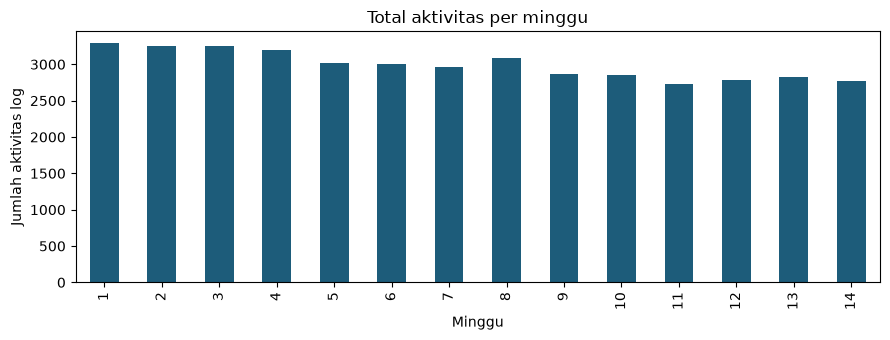

In [13]:
weekly = logs.groupby('minggu').size()
ax = weekly.plot(kind='bar', figsize=(9, 3.5), color='#1D5C7A')
ax.set_xlabel('Minggu')
ax.set_ylabel('Jumlah aktivitas log')
ax.set_title('Total aktivitas per minggu')
plt.tight_layout()
plt.show()

In [14]:
logs['action'].value_counts(normalize=True).round(3)

action
viewed       0.748
submitted    0.151
started      0.101
Name: proportion, dtype: float64

Sebagian besar aktivitas berupa melihat materi (`viewed`), sedangkan aktivitas mengerjakan kuis (`started` dan `submitted`) porsinya lebih kecil. Karena itu, fitur `aktivitas_7h` dan `aktivitas_14h` dihitung dari seluruh log, bukan hanya aktivitas kuis.

## 4. Distribusi nilai kuis

Hanya percobaan yang sudah selesai dan punya nilai yang dihitung.

count    6860.00
mean       58.49
std        11.25
min        19.71
25%        50.85
50%        58.25
75%        66.07
max       100.00
Name: sumgrades, dtype: float64


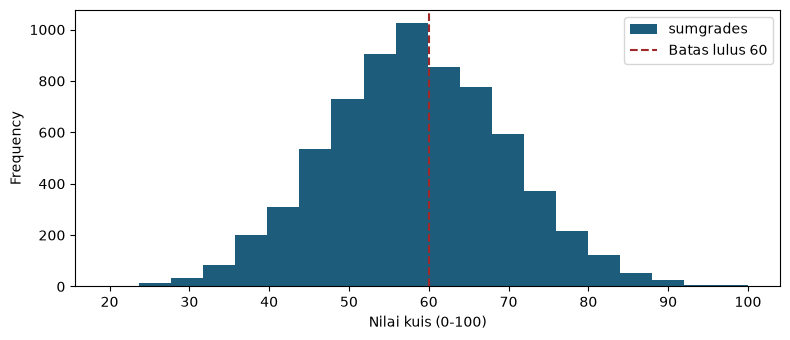

In [15]:
graded = attempts[(attempts['state'] == 'finished') & attempts['sumgrades'].notna()]
print(graded['sumgrades'].describe().round(2))

ax = graded['sumgrades'].plot(kind='hist', bins=20, figsize=(8, 3.5), color='#1D5C7A')
ax.axvline(60, color='#A1282A', linestyle='--', label='Batas lulus 60')
ax.legend()
ax.set_xlabel('Nilai kuis (0-100)')
plt.tight_layout()
plt.show()

Rata-rata nilai berada di sekitar 58 dengan simpangan sekitar 11. Batas 60 berada dekat pusat distribusi, sehingga bagian mahasiswa di bawah batas cukup besar. Ini menjelaskan mengapa proporsi label berisiko di `02_preprocessing.py` tinggi, dan mengapa hasil label sensitif terhadap ambang batas.

In [16]:
graded.groupby('minggu')['sumgrades'].mean().round(1)

minggu
1     57.9
2     58.1
3     58.2
4     57.4
5     58.5
6     58.4
7     58.7
8     57.9
9     58.9
10    58.5
11    59.7
12    59.4
13    59.1
14    58.7
Name: sumgrades, dtype: float64

Rata-rata nilai per minggu hampir stabil di sekitar 58 sampai 60. Tren kelas secara keseluruhan tidak kuat, sehingga perbedaan antar mahasiswa berasal dari masing-masing individu. Fitur `tren_nilai` per mahasiswa tetap diperlukan.

## 5. Pola berhenti aktif

Siswa dianggap berhenti jika log terakhirnya sebelum minggu 14.

In [17]:
last_week = logs.groupby('userid')['minggu'].max()
print('Siswa dengan log terakhir sebelum minggu 14:', int((last_week < 14).sum()))
print()
print(last_week.value_counts().sort_index())

Siswa dengan log terakhir sebelum minggu 14: 126

minggu
3      14
4       9
5      21
6       9
7      12
8      13
9      14
10     16
11     10
12      1
13      7
14    374
Name: count, dtype: int64


In [18]:
mean_grade = graded.groupby('userid')['sumgrades'].mean()
status = pd.DataFrame({'last_week': last_week, 'mean_grade': mean_grade})
status['berhenti'] = status['last_week'] < 14
status.groupby('berhenti')['mean_grade'].agg(['mean', 'count']).round(1)

,mean,count
berhenti,,
False,59.5,374
True,52.8,126


Mahasiswa yang berhenti memiliki rata-rata nilai lebih rendah. Pola ini ada karena generator menghubungkan kemampuan dengan keaktifan. Pada data Moodle asli, hubungan ini bisa lebih lemah atau berbeda, sehingga perlu diperiksa ulang saat data asli tersedia.

## 6. Ringkasan dan implikasi

- Data lengkap kecuali nilai kosong yang sudah diantisipasi di `02_preprocessing.py` dan `03_train_knn_mlp.py`.
- Batas lulus 60 berada dekat median nilai. Label sensitif terhadap ambang ini, sehingga laporan perlu menyertakan analisis sensitivitas dengan ambang lain.
- Keaktifan dan nilai saling berkaitan dalam data sintetis. Ini harus dicatat sebagai keterbatasan, karena pola nyata bisa berbeda.
- Fitur aktivitas dihitung dari seluruh log, dan fitur tren dihitung per mahasiswa.
- Notebook ini tidak menghasilkan file. Hasil yang dipakai di laporan dicatat dari output cell.